# Sipakarhutla — Notebook 3: Latih dan uji dengan data karhutla Indonesia

**Tujuan.** Menjawab pertanyaan yang gagal dijawab Notebook 2: *jika CNN dilatih dengan kejadian karhutla di Kalimantan yang citranya jernih, apakah ia bisa menilai tingkat keparahan kejadian Kalimantan yang belum pernah dilihatnya?*

**Data.** Enam kejadian dari Google Earth Engine (K002–K007; 2019 dan 2023, Kalimantan Tengah/Selatan), tiap kotak ±22 × 17 km, citra Sentinel-2 bersih (±99% piksel valid). Label Rendah/Sedang/Tinggi berasal dari dNBR.

**Cara menguji (leave-one-event-out).** Model dilatih pada 5 kejadian, lalu diuji pada 1 kejadian yang tidak ikut latih. Diulang untuk keenam kejadian. Dengan begitu setiap skor adalah skor pada *kejadian baru*.

**Yang perlu ada di folder `sipakarhutla_ml`:**
- `K002_2023_A_data.tif` ... `K007_2019_D_data.tif` (6 file dari Earth Engine, 6 pita: R, G, B, kelas, dNBR×1000, MODIS terbakar)
- *(opsional)* `model_as.pt` dari Notebook 1 — untuk pembanding "model AS tanpa latih ulang"
- *(opsional)* `K001_JabirenRaya_v2_rgb.tif` dan `K001_JabirenRaya_v2_kelas.tif` — untuk menguji Jabiren Raya (yang berkabut) di akhir

> **Peringatan.** Label dNBR dihitung dari satelit, bukan pengamatan lapangan. Skor di sini mengukur seberapa baik model meniru dNBR dari citra warna, bukan kebenaran mutlak di lapangan.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Persiapan

In [ ]:
import sys, subprocess, importlib
try: importlib.import_module('rasterio')
except ImportError: subprocess.check_call([sys.executable,'-m','pip','install','-q','rasterio'])
import os, glob, json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio, torch, torch.nn as nn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix, f1_score, recall_score, roc_auc_score

CEPAT = False      # True = uji coba cepat (kurang akurat, ±3x lebih cepat). False = hasil resmi.
SEED = 0
EPOCH = 4 if CEPAT else 6
LANGKAH_LATIH = 11 if CEPAT else 5     # patch latih saling tumpang tindih (5) agar data lebih banyak
np.random.seed(SEED); torch.manual_seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive'); BASE = '/content/drive/MyDrive/sipakarhutla_ml'
except ImportError:
    BASE = './sipakarhutla_ml'
NAMA_KELAS = ['Rendah', 'Sedang', 'Tinggi']
FILE = sorted(glob.glob(os.path.join(BASE, 'K00*_data.tif')))
print('Folder kerja:', os.path.abspath(BASE)); print('File kejadian:', [os.path.basename(f) for f in FILE])
assert len(FILE) >= 3, 'Perlu minimal 3 file K00x_..._data.tif di folder kerja'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja: /content/drive/MyDrive/sipakarhutla_ml
File kejadian: ['K002_2023_A_data.tif', 'K003_2023_B_data.tif', 'K004_2019_A_data.tif', 'K005_2019_B_data.tif', 'K006_2019_C_data.tif', 'K007_2019_D_data.tif']


## 2. Periksa data tiap kejadian

Tabel ini juga memeriksa **seberapa layak label dNBR dipercaya**. Kita bandingkan dNBR di area yang menurut MODIS tidak terbakar dan yang terbakar. Idealnya area "tidak terbakar" bernilai dNBR mendekati 0. Jika tinggi (mis. 0,3), berarti dNBR ikut menangkap perubahan non-api (musim, panen kebun, dll.) atau kebakaran kecil yang tidak terlihat MODIS, sehingga labelnya lebih meragukan.

In [ ]:
def blok(a, H3, W3):
    n = a.ndim
    return a.reshape(a.shape[:-2] + (H3 // 3, 3, W3 // 3, 3)).transpose(tuple(range(n - 2)) + (n - 2, n, n - 1, n + 1)).reshape(a.shape[:-2] + (H3 // 3, W3 // 3, 9))

def turunkan_30m(refl, K, valid):
    """Rata-ratakan 10 m -> 30 m (hanya piksel valid). Label blok 3x3 = suara terbanyak."""
    H3, W3 = K.shape
    v = blok(valid.astype(np.float32), H3, W3)
    r30 = blok(refl * valid, H3, W3).sum(-1) / np.maximum(v.sum(-1), 1)
    cnt = np.stack([(blok(np.where(valid, K, 0).astype(np.float32), H3, W3).astype(int) == c).sum(-1) for c in (1, 2, 3)], -1)
    return r30, cnt.argmax(-1), v.mean(-1) >= 0.67

P = 11
def potong(r30, l30, ok30, langkah):
    """Potong patch 11x11 (330 m). Dibuang bila <80% valid atau kelas terbanyak <50%."""
    h, w = ok30.shape; X, Y = [], []
    for i in range(0, h - P + 1, langkah):
        for j in range(0, w - P + 1, langkah):
            m = ok30[i:i+P, j:j+P]
            if m.mean() < 0.8: continue
            c = np.bincount(l30[i:i+P, j:j+P][m], minlength=3); lb = c.argmax()
            if c[lb] / m.sum() < 0.5: continue
            X.append(r30[:, i:i+P, j:j+P]); Y.append(lb)
    return np.array(X, np.float32), np.array(Y)

CACHE = os.path.join(BASE, f'patch_indo_L{LANGKAH_LATIH}.npz')
INFO, MINI, DATA = [], {}, {}
muat = np.load(CACHE, allow_pickle=True) if os.path.exists(CACHE) else None
for f in FILE:
    kode = os.path.basename(f).replace('_data.tif', '')
    a = rasterio.open(f).read(); H, W = a.shape[1:]; H3, W3 = H // 3 * 3, W // 3 * 3; a = a[:, :H3, :W3]
    K = a[3].astype(int); D = a[4] / 1000.0; M = a[5] > 0
    valid = (K > 0) & (a[:3].sum(0) > 0)
    INFO.append(dict(kejadian=kode, piksel_valid=valid.mean(),
        Rendah=(K[valid] == 1).mean(), Sedang=(K[valid] == 2).mean(), Tinggi=(K[valid] == 3).mean(),
        MODIS_terbakar=M[valid].mean(), dNBR_median_tak_terbakar=np.median(D[valid & ~M]), dNBR_median_terbakar=np.median(D[valid & M])))
    MINI[kode] = (a[:3, ::6, ::6].transpose(1, 2, 0).astype(np.uint8), np.where(valid, K, 0)[::6, ::6])
    if muat is None:
        r30, l30, ok30 = turunkan_30m(a[:3].astype(np.float32) / 255 * 0.3, K, valid)
        DATA[kode] = {'uji': potong(r30, l30, ok30, 11), 'latih': potong(r30, l30, ok30, LANGKAH_LATIH)}
    else:
        DATA[kode] = {'uji': (muat[kode + '__Xu'], muat[kode + '__Yu']), 'latih': (muat[kode + '__Xl'], muat[kode + '__Yl'])}
    print('selesai', kode)
if muat is None:
    np.savez_compressed(CACHE, **{f'{k}__{n}': v for k, d in DATA.items() for n, v in zip(['Xu', 'Yu'], d['uji']) } ,
                        **{f'{k}__{n}': v for k, d in DATA.items() for n, v in zip(['Xl', 'Yl'], d['latih'])})
EV = list(DATA)
pd.DataFrame(INFO).round(3)

selesai K002_2023_A
selesai K003_2023_B
selesai K004_2019_A
selesai K005_2019_B
selesai K006_2019_C
selesai K007_2019_D


,kejadian,piksel_valid,Rendah,Sedang,Tinggi,MODIS_terbakar,dNBR_median_tak_terbakar,dNBR_median_terbakar
0,K002_2023_A,0.993,0.329,0.149,0.523,0.424,0.299,0.621
1,K003_2023_B,0.995,0.660,0.044,0.296,0.385,0.083,0.697
2,K004_2019_A,0.997,0.549,0.083,0.368,0.485,0.068,0.626
3,K005_2019_B,0.996,0.701,0.063,0.236,0.343,0.051,0.498
4,K006_2019_C,0.998,0.420,0.290,0.290,0.328,0.283,0.369
5,K007_2019_D,0.996,0.796,0.077,0.127,0.270,0.034,0.358


**Cara membaca tabel.** Kolom `dNBR_median_tak_terbakar` yang jauh dari 0 (mis. K002 dan K006, sekitar 0,3) berarti label kejadian itu lebih berisik. Kolom `dNBR_median_terbakar` yang tinggi (≥ 0,5) berarti dNBR memisahkan terbakar dan tak terbakar dengan jelas. Kejadian dengan label berisik sebaiknya tidak dijadikan satu-satunya dasar kesimpulan.

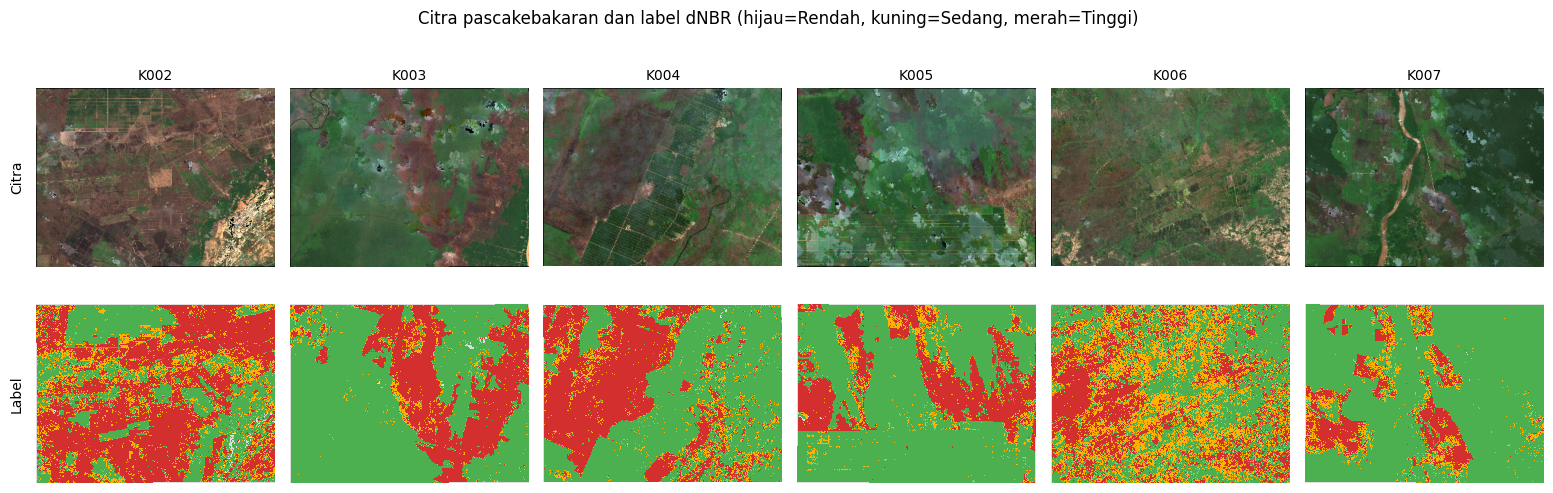

,kejadian,patch_uji,Rendah,Sedang,Tinggi,patch_latih
0,K002_2023_A,3003,1040,136,1827,14432
1,K003_2023_B,3273,2219,33,1021,15621
2,K004_2019_A,3133,1864,39,1230,15076
3,K005_2019_B,3243,2364,75,804,15526
4,K006_2019_C,2688,1346,573,769,12830
5,K007_2019_D,3212,2686,123,403,15310


PERHATIAN: kelas Sedang jarang pada banyak kejadian (dNBR cenderung dua kutub: tak terbakar atau sangat terbakar).


In [ ]:
fig, ax = plt.subplots(2, len(EV), figsize=(2.6 * len(EV), 5.4))
from matplotlib.colors import ListedColormap
cm = ListedColormap(['#dddddd', '#4caf50', '#ffb300', '#d32f2f'])
for c, k in enumerate(EV):
    rgb, kl = MINI[k]
    ax[0, c].imshow(np.clip(rgb / 255 * 1.6, 0, 1)); ax[0, c].set_title(k[:4], fontsize=10); ax[0, c].axis('off')
    ax[1, c].imshow(kl, cmap=cm, vmin=0, vmax=3, interpolation='nearest'); ax[1, c].axis('off')
ax[0, 0].text(-0.05, 0.5, 'Citra', transform=ax[0, 0].transAxes, rotation=90, ha='right', va='center')
ax[1, 0].text(-0.05, 0.5, 'Label', transform=ax[1, 0].transAxes, rotation=90, ha='right', va='center')
plt.suptitle('Citra pascakebakaran dan label dNBR (hijau=Rendah, kuning=Sedang, merah=Tinggi)'); plt.tight_layout(); plt.show()

baris = []
for k in EV:
    Yu = DATA[k]['uji'][1]; n = np.bincount(Yu, minlength=3)
    baris.append(dict(kejadian=k, patch_uji=len(Yu), Rendah=n[0], Sedang=n[1], Tinggi=n[2], patch_latih=len(DATA[k]['latih'][1])))
display(pd.DataFrame(baris))
print('PERHATIAN: kelas Sedang jarang pada banyak kejadian (dNBR cenderung dua kutub: tak terbakar atau sangat terbakar).')

## 3. Model dan fungsi latih

Arsitektur CNN sama dengan Notebook 1. Bobot kelas dipakai agar kelas langka tidak diabaikan, dan patch dibalik/diputar secara acak saat latihan (augmentasi).

In [ ]:
class Net(nn.Module):
    def __init__(s):
        super().__init__()
        def b(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        s.f = nn.Sequential(b(3, 32), b(32, 64), nn.MaxPool2d(2), b(64, 96), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3))
        s.c = nn.Linear(96, 3)
    def forward(s, x): return s.c(s.f(x))

def aug(x):
    if np.random.rand() < .5: x = torch.flip(x, [3])
    if np.random.rand() < .5: x = torch.flip(x, [2])
    return torch.rot90(x, np.random.randint(4), [2, 3])

def latih(net, X, Y, epoch, lr, mu, sd, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    Xn = torch.tensor((np.clip(X, 0, 1) - mu) / sd, dtype=torch.float32); Yt = torch.tensor(Y)
    w = torch.tensor(len(Y) / (3 * np.maximum(np.bincount(Y, minlength=3), 1)), dtype=torch.float32)
    opt = torch.optim.AdamW(net.parameters(), lr / 2, weight_decay=1e-3)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epoch * ((len(Y) + 255) // 256)); lf = nn.CrossEntropyLoss(weight=w)
    for e in range(epoch):
        net.train(); p = np.random.permutation(len(Y))
        for i in range(0, len(p), 256):
            ix = p[i:i+256]; opt.zero_grad(); lf(net(aug(Xn[ix])), Yt[ix]).backward(); opt.step(); sch.step()
    return net

def prob(net, X, mu, sd):
    net.eval(); xt = torch.tensor((np.clip(X, 0, 1) - mu) / sd, dtype=torch.float32)
    with torch.no_grad(): return torch.softmax(net(xt), 1).numpy()

def fitur(X):      # 9 angka warna: rata-rata, simpangan baku, rasio (untuk model pembanding)
    m = X.mean((2, 3)); s = X.std((2, 3)); j = m.sum(1, keepdims=True)
    return np.concatenate([m, s, m[:, :1] / j, m[:, 1:2] / j, j], 1)

## 4. Uji: satu kejadian disisihkan bergantian

Untuk tiap kejadian: latih pada 5 kejadian lain, uji pada kejadian itu. Yang dibandingkan:
- **Mayoritas**: selalu menjawab kelas terbanyak.
- **Gradient Boosting (warna)**: hanya melihat 9 angka warna per patch, tanpa pola ruang.
- **CNN dari nol**: dilatih hanya dengan data Indonesia ini.
- **CNN AS tanpa latih ulang** (jika `model_as.pt` ada): model Notebook 1, langsung dipakai.

Perkiraan waktu: 15–30 menit di Colab (CPU). Kamu bisa membiarkannya berjalan.

In [ ]:
PAKAI_AS = os.path.exists(os.path.join(BASE, 'model_as.pt'))
if PAKAI_AS:
    MA = torch.load(os.path.join(BASE, 'model_as.pt'), map_location='cpu', weights_only=False)
    print('model_as.pt ditemukan: pembanding "CNN AS tanpa latih ulang" dipakai.')
NAMA_M = ['Mayoritas', 'Gradient Boosting (warna)', 'CNN dari nol (data Indonesia)'] + (['CNN AS tanpa latih ulang'] if PAKAI_AS else [])
PROB = {m: {} for m in NAMA_M}; YU = {}
t0 = time.time()
for e in EV:
    tr = [x for x in EV if x != e]
    Xtr = np.concatenate([DATA[x]['latih'][0] for x in tr]); Ytr = np.concatenate([DATA[x]['latih'][1] for x in tr])
    Xte, Yte = DATA[e]['uji']; YU[e] = Yte
    PROB['Mayoritas'][e] = np.tile(np.eye(3)[np.bincount(Ytr, minlength=3).argmax()], (len(Yte), 1))
    gb = HistGradientBoostingClassifier(max_iter=150, class_weight='balanced', random_state=SEED).fit(fitur(Xtr), Ytr)
    pg = np.zeros((len(Yte), 3)); pg[:, gb.classes_] = gb.predict_proba(fitur(Xte)); PROB['Gradient Boosting (warna)'][e] = pg
    mu = Xtr.mean((0, 2, 3), keepdims=True); sd = Xtr.std((0, 2, 3), keepdims=True)
    net = latih(Net(), Xtr, Ytr, EPOCH, 4e-3, mu, sd, SEED); PROB['CNN dari nol (data Indonesia)'][e] = prob(net, Xte, mu, sd)
    if PAKAI_AS:
        pr = 0
        for sdict in MA['state_dict']:
            n = Net(); n.load_state_dict(sdict); pr = pr + prob(n, Xte, MA['mu'], MA['sd']) / len(MA['state_dict'])
        PROB['CNN AS tanpa latih ulang'][e] = pr
    print(f'selesai: uji pada {e}  [{time.time()-t0:.0f} dtk]')

model_as.pt ditemukan: pembanding "CNN AS tanpa latih ulang" dipakai.
selesai: uji pada K002_2023_A  [306 dtk]
selesai: uji pada K003_2023_B  [602 dtk]
selesai: uji pada K004_2019_A  [900 dtk]
selesai: uji pada K005_2019_B  [1194 dtk]
selesai: uji pada K006_2019_C  [1497 dtk]
selesai: uji pada K007_2019_D  [1792 dtk]


## 5. Hasil

,model,akurasi,macro_F1,recall_Rendah,recall_Sedang,recall_Tinggi,AUC_Tinggi
0,Mayoritas,0.621,0.255,1.000,0.000,0.000,0.500
1,Gradient Boosting (warna),0.842,0.687,0.865,0.430,0.865,0.966
2,CNN dari nol (data Indonesia),0.841,0.709,0.852,0.626,0.855,0.974
3,CNN AS tanpa latih ulang,0.757,0.648,0.730,0.681,0.822,0.970


Pembanding: kecerahan saja memisahkan Tinggi dengan AUC 0.578 (arah terbaik).


,tebak Rendah,tebak Sedang,tebak Tinggi
asli Rendah,9818,1149,552
asli Sedang,224,613,142
asli Tinggi,142,734,5178


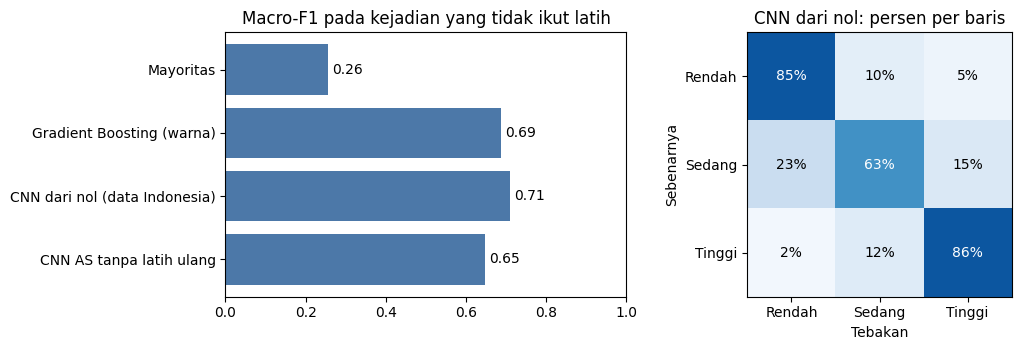

In [ ]:
Yp = np.concatenate([YU[e] for e in EV])
baris = []
for m in NAMA_M:
    Pm = np.concatenate([PROB[m][e] for e in EV]); pr = Pm.argmax(1); rc = recall_score(Yp, pr, average=None, labels=[0, 1, 2], zero_division=0)
    baris.append(dict(model=m, akurasi=np.mean(pr == Yp), macro_F1=f1_score(Yp, pr, average='macro', labels=[0, 1, 2], zero_division=0),
                      recall_Rendah=rc[0], recall_Sedang=rc[1], recall_Tinggi=rc[2], AUC_Tinggi=roc_auc_score(Yp == 2, Pm[:, 2])))
tabel = pd.DataFrame(baris).round(3); display(tabel)
Br = np.concatenate([DATA[e]['uji'][0].mean((1, 2, 3)) for e in EV])
print(f'Pembanding: kecerahan saja memisahkan Tinggi dengan AUC {max(roc_auc_score(Yp == 2, Br), roc_auc_score(Yp == 2, -Br)):.3f} (arah terbaik).')

nm = 'CNN dari nol (data Indonesia)'; PRED = np.concatenate([PROB[nm][e] for e in EV]).argmax(1)
cmx = confusion_matrix(Yp, PRED, labels=[0, 1, 2])
display(pd.DataFrame(cmx, index=['asli ' + n for n in NAMA_KELAS], columns=['tebak ' + n for n in NAMA_KELAS]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(tabel['model'][::-1], tabel['macro_F1'][::-1], color='#4c78a8'); ax[0].set_xlim(0, 1)
for i, v in enumerate(tabel['macro_F1'][::-1]): ax[0].text(v + .01, i, f'{v:.2f}', va='center')
ax[0].set_title('Macro-F1 pada kejadian yang tidak ikut latih')
cn = cmx / cmx.sum(1, keepdims=True); ax[1].imshow(cn, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3): ax[1].text(j, i, f'{cn[i,j]:.0%}', ha='center', va='center', color='white' if cn[i, j] > .5 else 'black')
ax[1].set_xticks(range(3), NAMA_KELAS); ax[1].set_yticks(range(3), NAMA_KELAS); ax[1].set_xlabel('Tebakan'); ax[1].set_ylabel('Sebenarnya'); ax[1].set_title('CNN dari nol: persen per baris')
plt.tight_layout(); plt.show()

**Cara membaca.** Fokus pada `macro_F1` (adil untuk kelas yang tidak seimbang) dan `recall_Sedang`. `AUC_Tinggi` mengukur seberapa baik model memisahkan Tinggi dari yang lain (0,5 = tebakan acak, 1 = sempurna). Bandingkan CNN dengan Gradient Boosting: selisihnya menunjukkan apa yang ditambahkan CNN di luar angka warna.

### Per kejadian

In [ ]:
baris = []
for e in EV:
    r = dict(kejadian=e, n=len(YU[e]))
    for m in NAMA_M[1:]:
        r['F1 ' + m.split(' (')[0]] = f1_score(YU[e], PROB[m][e].argmax(1), average='macro', labels=[0, 1, 2], zero_division=0)
    r['akurasi CNN'] = np.mean(PROB[nm][e].argmax(1) == YU[e]); baris.append(r)
pk = pd.DataFrame(baris).round(3); display(pk)
print('Macro-F1 per kejadian ikut dipengaruhi jumlah patch Sedang yang sangat sedikit pada banyak kejadian, jadi jangan dibaca terlalu rinci.')

,kejadian,n,F1 Gradient Boosting,F1 CNN dari nol,F1 CNN AS tanpa latih ulang,akurasi CNN
0,K002_2023_A,3003,0.463,0.487,0.468,0.714
1,K003_2023_B,3273,0.672,0.699,0.628,0.925
2,K004_2019_A,3133,0.682,0.676,0.616,0.895
3,K005_2019_B,3243,0.687,0.732,0.597,0.931
4,K006_2019_C,2688,0.612,0.597,0.644,0.646
5,K007_2019_D,3212,0.712,0.723,0.641,0.896


Macro-F1 per kejadian ikut dipengaruhi jumlah patch Sedang yang sangat sedikit pada banyak kejadian, jadi jangan dibaca terlalu rinci.


## 6. Ambang keyakinan dan "menunggu ahli"

Di aplikasi, model hanya memutuskan sendiri bila keyakinan tertingginya ≥ ambang; di bawah itu titik masuk "menunggu ahli". Tabel menunjukkan tukar tambahnya pada data Indonesia ini.

,ambang,persen_diputuskan_model,akurasi_diputuskan,macro_F1_diputuskan,recall_Sedang,akurasi_ditunda
0,0.5,0.980,0.851,0.718,0.632,0.379
1,0.6,0.917,0.877,0.738,0.635,0.451
2,0.7,0.853,0.900,0.753,0.625,0.500
3,0.8,0.778,0.928,0.777,0.611,0.538
4,0.9,0.680,0.959,0.792,0.488,0.592


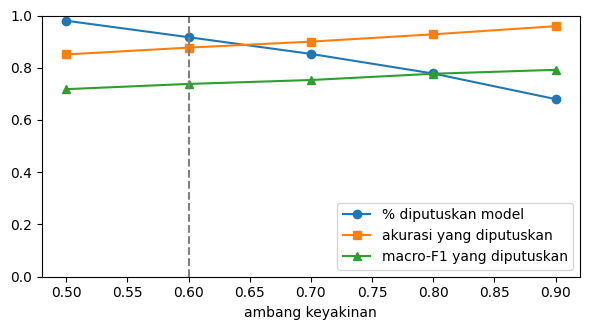

In [ ]:
PR = np.concatenate([PROB[nm][e] for e in EV]); KONF = PR.max(1); baris = []
for t in (0.5, 0.6, 0.7, 0.8, 0.9):
    mk = KONF >= t
    baris.append(dict(ambang=t, persen_diputuskan_model=mk.mean(), akurasi_diputuskan=np.mean(PRED[mk] == Yp[mk]),
                      macro_F1_diputuskan=f1_score(Yp[mk], PRED[mk], average='macro', labels=[0, 1, 2], zero_division=0),
                      recall_Sedang=recall_score(Yp[mk], PRED[mk], average=None, labels=[0, 1, 2], zero_division=0)[1],
                      akurasi_ditunda=np.mean(PRED[~mk] == Yp[~mk])))
tt = pd.DataFrame(baris).round(3); display(tt)
plt.figure(figsize=(6, 3.4)); plt.plot(tt.ambang, tt.persen_diputuskan_model, 'o-', label='% diputuskan model')
plt.plot(tt.ambang, tt.akurasi_diputuskan, 's-', label='akurasi yang diputuskan'); plt.plot(tt.ambang, tt.macro_F1_diputuskan, '^-', label='macro-F1 yang diputuskan')
plt.axvline(0.6, ls='--', c='gray'); plt.ylim(0, 1); plt.xlabel('ambang keyakinan'); plt.legend(); plt.tight_layout(); plt.show()

## 7. Latih model akhir dan simpan

Model untuk aplikasi dilatih pada **semua** kejadian. Skor resmi tetap yang dari bagian 4 (kejadian disisihkan), bukan dari model akhir ini.

In [ ]:
Xa = np.concatenate([DATA[x]['latih'][0] for x in EV]); Ya = np.concatenate([DATA[x]['latih'][1] for x in EV])
MUI = Xa.mean((0, 2, 3), keepdims=True); SDI = Xa.std((0, 2, 3), keepdims=True)
NET_AKHIR = latih(Net(), Xa, Ya, EPOCH, 4e-3, MUI, SDI, SEED)
torch.save({'state_dict': NET_AKHIR.state_dict(), 'mu': MUI, 'sd': SDI, 'kelas': NAMA_KELAS}, os.path.join(BASE, 'model_indo.pt'))
with open(os.path.join(BASE, 'ringkasan_indo.json'), 'w') as fh:
    json.dump({'tabel_model': tabel.to_dict('records'), 'ambang': tt.to_dict('records'), 'kejadian': EV}, fh, indent=1)
print('Tersimpan:', sorted(f for f in os.listdir(BASE) if 'indo' in f))

Tersimpan: ['model_indo.pt', 'patch_indo_L5.npz', 'ringkasan_indo.json']


## 8. Uji akhir: Jabiren Raya (berkabut)

Model akhir dicoba pada Jabiren Raya 2026 yang citranya berkabut. Ini bukan uji bersih: label dNBR Jabiren Raya sendiri terpengaruh kabut. Gunanya hanya melihat apakah model dari citra jernih masih berguna pada citra berkabut.

In [ ]:
fr, fk = [os.path.join(BASE, n) for n in ('K001_JabirenRaya_v2_rgb.tif', 'K001_JabirenRaya_v2_kelas.tif')]
if os.path.exists(fr) and os.path.exists(fk):
    rgb = rasterio.open(fr).read().astype(np.float32); K = rasterio.open(fk).read(1).astype(int)
    H, W = K.shape; H3, W3 = H // 3 * 3, W // 3 * 3; rgb, K = rgb[:, :H3, :W3], K[:H3, :W3]
    valid = (K > 0) & (rgb.sum(0) > 0)
    r30, l30, ok30 = turunkan_30m(rgb / 255 * 0.3, K, valid); Xj, Yj = potong(r30, l30, ok30, 11)
    pj = prob(NET_AKHIR, Xj, MUI, SDI); pp = pj.argmax(1)
    print(f'Jabiren Raya: {len(Yj)} patch, kelas {np.bincount(Yj, minlength=3).tolist()} | kecerahan {Xj.mean():.3f} (data Indonesia jernih: {Xa.mean():.3f})')
    print(f'akurasi {np.mean(pp == Yj):.3f} | macro-F1 {f1_score(Yj, pp, average="macro", labels=[0,1,2], zero_division=0):.3f} | recall {recall_score(Yj, pp, average=None, labels=[0,1,2], zero_division=0).round(2).tolist()} | yakin >= 0,60: {(pj.max(1) >= .6).mean():.1%}')
    display(pd.DataFrame(confusion_matrix(Yj, pp, labels=[0, 1, 2]), index=['asli ' + n for n in NAMA_KELAS], columns=['tebak ' + n for n in NAMA_KELAS]))
else:
    print('File K001_JabirenRaya_v2_rgb.tif / _kelas.tif tidak ada di folder kerja; bagian ini dilewati.')

Jabiren Raya: 851 patch, kelas [761, 35, 55] | kecerahan 0.161 (data Indonesia jernih: 0.056)
akurasi 0.645 | macro-F1 0.432 | recall [0.65, 0.23, 0.87] | yakin >= 0,60: 68.0%


,tebak Rendah,tebak Sedang,tebak Tinggi
asli Rendah,493,178,90
asli Sedang,3,8,24
asli Tinggi,0,7,48


## Ringkasan untuk laporan
- Dengan citra jernih dan data dari domain yang sama (Kalimantan), CNN menilai kejadian yang belum pernah dilihat jauh lebih baik dibanding model dari data AS. Baca angkanya di tabel bagian 5.
- Bandingkan CNN dengan Gradient Boosting (warna saja). Jelaskan apa tambahan CNN dan seberapa besar.
- Ambang keyakinan (bagian 6) menukar cakupan dengan akurasi.
- **Keterbatasan yang wajib disebut:**
  1. Label berasal dari dNBR satelit, bukan survei lapangan.
  2. Hanya 6 kejadian, semuanya di Kalimantan Tengah/Selatan dan di lanskap gambut yang mirip, jadi belum membuktikan generalisasi ke seluruh Indonesia.
  3. Kelas Sedang sangat jarang; angka Sedang kasar.
  4. Dua kejadian (K002 dan K006) punya dNBR dasar yang tinggi pada area tak terbakar, jadi labelnya lebih berisik.
  5. Citra berkabut (Jabiren Raya) tetap sulit; sistem butuh citra pascakebakaran yang jernih.